<a href="https://colab.research.google.com/github/siaelkhattat/TRACEMEET/blob/main/02_miccheck_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MicCheck: acoustic verification of speaker attribution in AI meeting summaries

**Executable research notebook.** This notebook asks whether synchronized participant
microphones can flag a summary claim such as *“S017 proposed the comedy”* when the audible
voice is actually another participant.

The notebook implements the complete, frozen comparison:

1. **Reference baseline:** raw microphone-energy dominance.
2. **Advanced model:** pretrained ECAPA-TDNN speaker embeddings.
3. **Proposed model:** a calibrated logistic fusion of energy, dominance, and voice identity.
4. **Ablation:** energy cues only, voice cue only, and their fusion.
5. **Sensitivity:** evidence-window size and flagging coverage.
6. **Error analysis:** automatically selected false-positive and false-negative examples.

No numerical result in this notebook is synthetic. The controlled benchmark is created from
aligned SUMM-RE gold evidence and counterfactual speaker substitutions. Natural LLM claims are
evaluated only after a human fills the annotation sheet generated below.

## tl;dr

Run all cells in Google Colab (a T4 GPU is sufficient). The notebook downloads only the selected
SUMM-RE meetings, caches expensive embeddings, writes paper-ready tables and figures to
`paper/generated/`, and writes detailed audit tables to `outputs/reports/miccheck/`.

**Important:** this notebook does not state a finding before the real audio has been processed.
After execution, the result cells and exported LaTeX macros contain the measured findings.

## Context & Methods

### 1. Environment setup

In [3]:
# Colab: run once per fresh runtime. Local users may skip if dependencies are installed.
import sys, subprocess, importlib.util

REQUIRED = {
    "speechbrain": "speechbrain>=1.0.0",
    "sklearn": "scikit-learn>=1.3",
    "seaborn": "seaborn>=0.13",
    "soundfile": "soundfile>=0.12",
    "huggingface_hub": "huggingface_hub>=0.20",
    "pyarrow": "pyarrow>=14",
}
missing = [pkg for module, pkg in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Dependencies ready.")

Dependencies ready.


In [4]:
%cd /content
!test -d TRACEMEET || git clone https://github.com/siaelkhattat/TRACEMEET.git

%cd /content/TRACEMEET
!git pull

%pip install -q -r requirements.txt
%pip install -q -e .

import sys
import importlib
from pathlib import Path

REPO_ROOT = Path("/content/TRACEMEET").resolve()
SRC_ROOT = REPO_ROOT / "src"

sys.path.insert(0, str(SRC_ROOT))
importlib.invalidate_caches()

import tracemeet
print("TraceMeet loaded from:", tracemeet.__file__)

/content
Cloning into 'TRACEMEET'...
remote: Enumerating objects: 131, done.
remote: Counting objects: 100% (131/131), done.
remote: Compressing objects: 100% (82/82), done.
remote: Total 131 (delta 52), reused 105 (delta 27), pack-reused 0 (from 0)
Receiving objects: 100% (131/131), 38.09 KiB | 5.44 MiB/s, done.
Resolving deltas: 100% (52/52), done.
/content/TRACEMEET
Already up to date.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tracemeet (pyproject.toml) ... done
TraceMeet loaded from: /content/TRACEMEET/src/tracemeet/__init__.py


### 2. Frozen study configuration

In [5]:
from dataclasses import dataclass
import json, math, random, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns

from tracemeet.config import load_config
from tracemeet.evaluation.asr_metrics import strip_gold_markup

SEED = 2026
rng = np.random.default_rng(SEED)
random.seed(SEED)

@dataclass(frozen=True)
class StudyConfig:
    enrollment_seconds: float = 120.0
    max_time_seconds: float = 900.0
    events_per_meeting: int = 30
    min_words: int = 5
    min_duration: float = 1.0
    max_duration: float = 10.0
    frame_seconds: float = 0.02
    dominance_tolerance_db: float = 3.0
    evidence_pad_seconds: float = 1.0
    bootstrap_iterations: int = 1000
    ecapa_model: str = "speechbrain/spkrec-ecapa-voxceleb"

STUDY = StudyConfig()
CFG = load_config()
RAW_ROOT = CFG["paths"]["raw"] / "summre"
REPORT_ROOT = CFG["paths"]["reports_out"] / "miccheck"
PAPER_ROOT = REPO_ROOT / "paper" / "generated"
CACHE_ROOT = CFG["paths"]["interim"] / "miccheck"
for directory in (REPORT_ROOT, PAPER_ROOT, CACHE_ROOT):
    directory.mkdir(parents=True, exist_ok=True)

SPLITS = json.loads((CFG["paths"]["splits"] / "selected_meetings.json").read_text())
MEETING_SPLIT = {m: s for s, meetings in SPLITS.items() for m in meetings}
COLOCATED = [m for m in MEETING_SPLIT if m[-1] in {"H", "L"}]
REMOTE_CONTROLS = [m for m in MEETING_SPLIT if m[-1] == "Z"]
DEV_MEETINGS = [m for m in SPLITS["dev"] if m in COLOCATED]
TEST_MEETINGS = [m for m in SPLITS["test"] if m in COLOCATED]

print("Development (co-located):", DEV_MEETINGS)
print("Final test (co-located):", TEST_MEETINGS)
print("Remote negative control:", REMOTE_CONTROLS)

Development (co-located): ['006b_EADH']
Final test (co-located): ['025b_EBDH', '039b_EDDH', '045b_EADH']
Remote negative control: ['020b_EBDZ']


### Key assumptions

- All participant tracks are synchronized 16 kHz mono recordings.
- Track identity is known from the recording setup; this is **not** diarization.
- The first two minutes are reserved for automatic speaker enrollment and excluded from evaluation.
- Thresholds and fusion weights are fitted only on development meetings.
- Test meetings remain untouched until final evaluation.
- The primary endpoint is AUROC for detecting misattribution; AUPRC and thresholded metrics are secondary.
- Confidence intervals resample meetings, not individual claims, to respect within-meeting dependence.

## Data

### 3. Fetch the selected SUMM-RE meetings

In [6]:
# This downloads only parquet shards containing the five selected meetings and caches audio.
# In Colab, set TRACEMEET_DATA_ROOT to Drive before running if persistent storage is desired.
import subprocess

missing_meetings = [m for m in MEETING_SPLIT if not (RAW_ROOT / m / "meta.json").exists()]
if missing_meetings:
    print("Missing meetings:", missing_meetings)
    print("Fetching the selected 15-minute excerpts...")
    subprocess.check_call([sys.executable, "scripts/fetch_meetings.py"])
else:
    print("All selected meetings are present.")

assert all((RAW_ROOT / m / "gold_segments.json").exists() for m in MEETING_SPLIT), \
    "SUMM-RE download incomplete. Re-run this cell after checking network/Drive space."

Missing meetings: ['006b_EADH', '020b_EBDZ', '025b_EBDH', '039b_EDDH', '045b_EADH']
Fetching the selected 15-minute excerpts...


### 4. Audio and gold-evidence helpers

In [8]:
SR = 16_000

def load_tracks(meeting):
    paths = sorted((RAW_ROOT / meeting / "tracks").glob("*.wav"))
    tracks = {p.stem: sf.read(p, dtype="float32")[0] for p in paths}
    if not tracks:
        raise FileNotFoundError(f"No participant tracks for {meeting}")
    return tracks

def load_gold_rows(meeting):
    payload = json.loads((RAW_ROOT / meeting / "gold_segments.json").read_text())
    rows = []
    for speaker, segments in payload.items():
        for segment in segments:
            text = " ".join(strip_gold_markup(segment["transcript"]).split())
            if text:
                rows.append({
                    "meeting": meeting,
                    "true_speaker": str(speaker),
                    "start": float(segment["start"]),
                    "end": float(segment["end"]),
                    "claim": text,
                })
    return sorted(rows, key=lambda row: (row["start"], row["end"]))

def rms_db(audio):
    return float(20 * np.log10(np.sqrt(np.mean(np.square(audio))) + 1e-9)) if len(audio) else -120.0

def audio_slice(audio, start, end):
    left = max(0, int(start * SR))
    right = min(len(audio), max(left + 1, int(end * SR)))
    return audio[left:right]

def stable_id(*parts):
    return hashlib.sha1("|".join(map(str, parts)).encode()).hexdigest()[:12]

### 5. Controlled counterfactual benchmark

Each selected gold evidence segment produces two paired examples:

- **Correct:** the claim keeps its true speaker.
- **Misattributed:** the speaker is replaced by the non-speaker microphone with the highest energy
  during the same evidence interval. This is a deliberately difficult *bleed negative*.

A random-speaker counterpart is the primary controlled benchmark because it does not select
errors using the baseline feature. The highest-energy *hard bleed negative* is retained only as a
stress test: selecting it by energy would otherwise give the energy baseline an unfair advantage.
The text and time are held constant, so the only manipulated variable is the claimed speaker.

In [9]:
def choose_events(meeting, n_events):
    candidates = [row for row in load_gold_rows(meeting)
                  if row["start"] >= STUDY.enrollment_seconds
                  and row["end"] <= STUDY.max_time_seconds
                  and STUDY.min_duration <= row["end"] - row["start"] <= STUDY.max_duration
                  and len(row["claim"].split()) >= STUDY.min_words]
    if len(candidates) <= n_events:
        return candidates
    local_rng = np.random.default_rng(SEED + int(meeting[:3]))
    chosen = local_rng.choice(len(candidates), size=n_events, replace=False)
    return [candidates[i] for i in sorted(chosen)]

def counterfactual_rows(meeting):
    tracks = load_tracks(meeting)
    speakers = sorted(tracks)
    records = []
    local_rng = np.random.default_rng(SEED + 10_000 + int(meeting[:3]))
    for event in choose_events(meeting, STUDY.events_per_meeting):
        levels = {speaker: rms_db(audio_slice(audio, event["start"], event["end"]))
                  for speaker, audio in tracks.items()}
        alternatives = [speaker for speaker in speakers if speaker != event["true_speaker"]]
        hard_speaker = max(alternatives, key=levels.get)
        random_speaker = str(local_rng.choice(alternatives))
        event_id = stable_id(meeting, event["start"], event["end"], event["claim"])
        for benchmark, wrong_speaker in (("counterfactual_hard", hard_speaker),
                                         ("counterfactual_random", random_speaker)):
            common = {**event, "event_id": event_id, "benchmark": benchmark,
                      "split": MEETING_SPLIT[meeting]}
            records.append({**common, "claim_id": event_id + "_ok_" + benchmark[-4:],
                            "claimed_speaker": event["true_speaker"], "label": "correct", "y": 0})
            records.append({**common, "claim_id": event_id + "_bad_" + benchmark[-4:],
                            "claimed_speaker": wrong_speaker, "label": "misattributed", "y": 1})
    return records

benchmark = pd.DataFrame([
    record for meeting in MEETING_SPLIT for record in counterfactual_rows(meeting)
])
benchmark.to_csv(REPORT_ROOT / "counterfactual_claims.csv", index=False)
display(benchmark.groupby(["benchmark", "split", "meeting", "label"]).size()
        .rename("claims").reset_index())

,benchmark,split,meeting,label,claims
0,counterfactual_hard,dev,006b_EADH,correct,30
1,counterfactual_hard,dev,006b_EADH,misattributed,30
2,counterfactual_hard,dev,020b_EBDZ,correct,30
3,counterfactual_hard,dev,020b_EBDZ,misattributed,30
4,counterfactual_hard,test,025b_EBDH,correct,30
5,counterfactual_hard,test,025b_EBDH,misattributed,30
6,counterfactual_hard,test,039b_EDDH,correct,30
7,counterfactual_hard,test,039b_EDDH,misattributed,30
8,counterfactual_hard,test,045b_EADH,correct,30
9,counterfactual_hard,test,045b_EADH,misattributed,30


In [12]:
%cd /content/TRACEMEET

# Install the CUDA libraries required by faster-whisper.
# This can take several minutes because cuDNN is large.
%pip install -q nvidia-cublas-cu12 "nvidia-cudnn-cu12==9.*"

import os
import sys
import subprocess
import nvidia.cublas
import nvidia.cudnn

# Locate the pip-installed CUDA libraries.
cublas_lib = os.path.join(
    os.path.dirname(nvidia.cublas.__path__[0]),
    "cublas",
    "lib",
)

cudnn_lib = os.path.join(
    os.path.dirname(nvidia.cudnn.__path__[0]),
    "cudnn",
    "lib",
)

cuda_library_path = f"{cublas_lib}:{cudnn_lib}"

# Make the libraries visible to every later subprocess, including Qwen.
previous_path = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = (
    f"{cuda_library_path}:{previous_path}"
    if previous_path
    else cuda_library_path
)

print("CUDA libraries configured:")
print("cuBLAS:", cublas_lib)
print("cuDNN: ", cudnn_lib)
print("\nResuming Whisper with live output...\n")

command = [
    sys.executable,
    "-u",
    "scripts/run_asr.py",
    "--model", "large-v3",
    "--split", "all",
]

process = subprocess.Popen(
    command,
    cwd="/content/TRACEMEET",
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
    env=os.environ.copy(),
)

for line in process.stdout:
    print(line, end="")

return_code = process.wait()

if return_code == 0:
    print("\nWhisper ASR completed successfully.")
else:
    print(f"\nWhisper failed with exit code {return_code}.")

/content/TRACEMEET
CUDA libraries configured:
cuBLAS: /usr/local/lib/python3.13/dist-packages/nvidia/cublas/lib
cuDNN:  /usr/local/lib/python3.13/dist-packages/nvidia/cudnn/lib

Resuming Whisper with live output...

loading faster-whisper 'large-v3' on cuda (float16)
006b_EADH mix: 900s audio in 111.7s
006b_EADH track:017: 900s audio in 70.0s
006b_EADH track:018: 900s audio in 57.6s
006b_EADH track:019: 900s audio in 56.0s
006b_EADH track:020: 900s audio in 53.3s
020b_EBDZ mix: 900s audio in 109.8s
020b_EBDZ track:017: 900s audio in 44.6s
020b_EBDZ track:053: 900s audio in 43.0s
020b_EBDZ track:057: 900s audio in 22.5s
020b_EBDZ track:063: 900s audio in 4.1s
025b_EBDH mix: 900s audio in 92.2s
025b_EBDH track:071: 900s audio in 57.2s
025b_EBDH track:072: 900s audio in 58.9s
025b_EBDH track:073: 900s audio in 52.2s
025b_EBDH track:074: 900s audio in 61.6s
039b_EDDH mix: 900s audio in 96.8s
039b_EDDH track:104: 900s audio in 69.6s
039b_EDDH track:105: 900s audio in 32.3s
039b_EDDH track:1

In [14]:
# ============================================================
# Generate raw ASR, Qwen claims, and automatic silver labels
# ============================================================

%cd /content/TRACEMEET

%pip install -q -r requirements-colab.txt
%pip install -q speechbrain
%pip install -q -e .

import sys
import os
import json
import hashlib
import subprocess
import importlib
from pathlib import Path

import pandas as pd

# Make the local src/ package immediately visible to this kernel.
REPO_ROOT = Path("/content/TRACEMEET").resolve()
SRC_ROOT = REPO_ROOT / "src"

if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

importlib.invalidate_caches()

from tracemeet.config import load_config

print("Repository:", REPO_ROOT)

# ------------------------------------------------------------
# 1. Run Whisper large-v3 on all selected meetings
# Existing outputs are skipped automatically.
# ------------------------------------------------------------

print("\n[1/4] Running Whisper large-v3...")
subprocess.run(
    [
        sys.executable,
        "scripts/run_asr.py",
        "--model", "large-v3",
        "--split", "all",
    ],
    check=True,
)

# ------------------------------------------------------------
# 2. Generate attributed claims with Qwen3-8B
# Missing masked-ASR messages are acceptable: this cell needs
# the asr_raw claims only.
# ------------------------------------------------------------

print("\n[2/4] Generating attributed claims with Qwen3-8B...")
subprocess.run(
    [sys.executable, "scripts/attr_generate.py"],
    check=True,
)

# ------------------------------------------------------------
# 3. Match each generated claim against nearby gold transcript
# chunks using multilingual semantic embeddings.
#
# attr_score.py produces:
#   correct / misattributed / unverifiable
#   top_speaker
#   top_sim / own_sim
# ------------------------------------------------------------

print("\n[3/4] Producing automatic semantic labels...")
subprocess.run(
    [sys.executable, "scripts/attr_score.py"],
    check=True,
)

# ------------------------------------------------------------
# 4. Convert automatic results into Cell 6's expected CSV
# ------------------------------------------------------------

print("\n[4/4] Building the natural-claims annotation CSV...")

cfg = load_config()

scores_path = cfg["paths"]["reports_out"] / "attribution_claims.csv"
output_path = (
    cfg["paths"]["annotations"]
    / "miccheck_natural_claims.csv"
)

if not scores_path.exists():
    raise FileNotFoundError(
        f"Automatic attribution results were not created: {scores_path}"
    )

scores = pd.read_csv(
    scores_path,
    dtype={
        "meeting": str,
        "cond": str,
        "speaker": str,
        "top_speaker": str,
        "claim": str,
        "label": str,
    },
)

# Only actual claims generated from raw Whisper transcripts.
scores = scores[scores["cond"] == "asr_raw"].copy()

if scores.empty:
    raise RuntimeError(
        "No asr_raw claims were found. Check the output of "
        "run_asr.py and attr_generate.py above."
    )

selected = json.loads(
    (cfg["paths"]["splits"] / "selected_meetings.json").read_text()
)

meeting_split = {
    meeting: split_name
    for split_name, meetings in selected.items()
    for meeting in meetings
}


def normalize_speaker(value):
    """Normalize S017, 017, or 17 to the track identifier."""
    if pd.isna(value):
        return ""

    value = str(value).strip()

    if value.lower() == "nan":
        return ""

    return value.removeprefix("S")


def make_claim_id(meeting, index, speaker, time, claim):
    raw = f"{meeting}|{index}|{speaker}|{time}|{claim}"
    return hashlib.sha1(raw.encode("utf-8")).hexdigest()[:12]


def load_asr_segments(meeting):
    """Load raw per-speaker Whisper segments for one meeting."""
    tracks_root = (
        cfg["paths"]["asr_out"]
        / "large-v3"
        / meeting
        / "tracks"
    )

    segments = []

    for path in sorted(tracks_root.glob("*.json")):
        speaker = path.stem
        payload = json.loads(path.read_text())

        for segment in payload.get("segments", []):
            segments.append(
                {
                    "speaker": speaker,
                    "start": float(segment["start"]),
                    "end": float(segment["end"]),
                    "text": segment.get("text", ""),
                }
            )

    return segments


asr_cache = {}
records = []

for index, row in scores.reset_index(drop=True).iterrows():
    meeting = str(row["meeting"])
    claimed_speaker = normalize_speaker(row["speaker"])
    top_speaker = normalize_speaker(row.get("top_speaker", ""))
    time = float(row["time"])
    claim = str(row["claim"]).strip()
    label = str(row["label"]).strip().lower()

    if meeting not in asr_cache:
        asr_cache[meeting] = load_asr_segments(meeting)

    # Find the Whisper segment associated with the claimed speaker
    # and closest to the claim's supplied timestamp.
    candidates = [
        segment
        for segment in asr_cache[meeting]
        if normalize_speaker(segment["speaker"]) == claimed_speaker
    ]

    if candidates:
        evidence = min(
            candidates,
            key=lambda segment: abs(segment["start"] - time),
        )
        start = evidence["start"]
        end = evidence["end"]
    else:
        # Safe fallback if Qwen supplied a timestamp without a matching
        # claimed-speaker ASR segment.
        start = max(0.0, time - 1.0)
        end = time + 4.0

    if label == "correct":
        true_speaker = claimed_speaker
    elif label == "misattributed":
        true_speaker = top_speaker
    else:
        true_speaker = ""

    top_sim = row.get("top_sim", float("nan"))
    own_sim = row.get("own_sim", float("nan"))

    comment = (
        "AUTO_SILVER_LABEL: semantic matching against nearby gold "
        f"transcript; top_sim={top_sim}; own_sim={own_sim}. "
        "This is not a human annotation."
    )

    records.append(
        {
            "claim_id": make_claim_id(
                meeting,
                index,
                claimed_speaker,
                time,
                claim,
            ),
            "meeting": meeting,
            "split": meeting_split.get(meeting, ""),
            "claimed_speaker": claimed_speaker,
            "time": time,
            "start": start,
            "end": end,
            "claim": claim,
            "label": label,
            "true_speaker": true_speaker,
            "comment": comment,
        }
    )

automatic_sheet = pd.DataFrame(records)

valid_labels = {
    "correct",
    "misattributed",
    "unverifiable",
}

unexpected_labels = (
    set(automatic_sheet["label"].unique())
    - valid_labels
)

if unexpected_labels:
    raise ValueError(
        f"Unexpected automatic labels: {unexpected_labels}"
    )

output_path.parent.mkdir(parents=True, exist_ok=True)
automatic_sheet.to_csv(output_path, index=False)

print("\nAutomatic silver-label CSV created:")
print(output_path)

print("\nLabel distribution:")
display(
    automatic_sheet["label"]
    .value_counts(dropna=False)
    .rename_axis("label")
    .reset_index(name="claims")
)

print("\nPreview:")
display(automatic_sheet.head(10))

/content/TRACEMEET
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tracemeet (pyproject.toml) ... done
Repository: /content/TRACEMEET

[1/4] Running Whisper large-v3...

[2/4] Generating attributed claims with Qwen3-8B...

[3/4] Producing automatic semantic labels...

[4/4] Building the natural-claims annotation CSV...

Automatic silver-label CSV created:
/content/TRACEMEET/data/annotations/miccheck_natural_claims.csv

Label distribution:


,label,claims
0,correct,56
1,misattributed,48
2,unverifiable,6



Preview:


,claim_id,meeting,split,claimed_speaker,time,start,end,claim,label,true_speaker,comment
0,2570b59e4ac1,006b_EADH,dev,017,123.0,122.50,125.72,Il faut essayer de penser à post-Covid.,correct,017,AUTO_SILVER_LABEL: semantic matching against n...
1,0fcf43918a07,006b_EADH,dev,018,145.0,145.38,146.76,On peut organiser l'événement en ligne.,correct,018,AUTO_SILVER_LABEL: semantic matching against n...
2,a1eb25f2f4df,006b_EADH,dev,017,148.0,147.44,148.12,C'est bien de le faire en direct quand même.,misattributed,019,AUTO_SILVER_LABEL: semantic matching against n...
3,4338e462b59d,006b_EADH,dev,017,157.0,157.66,159.92,Il faut faire une bonne publicité.,misattributed,019,AUTO_SILVER_LABEL: semantic matching against n...
4,ee92d797000f,006b_EADH,dev,019,160.0,159.90,160.56,"Il faut que ça soit bien connu, bien relayé pa...",correct,019,AUTO_SILVER_LABEL: semantic matching against n...
5,83d39390f642,006b_EADH,dev,017,171.0,171.34,175.00,On le fera l'automne prochain.,misattributed,018,AUTO_SILVER_LABEL: semantic matching against n...
6,602747d01efd,006b_EADH,dev,017,210.0,210.54,212.48,"On pourra faire dehors, c'est encore le Covid.",correct,017,AUTO_SILVER_LABEL: semantic matching against n...
7,36ce7f389752,006b_EADH,dev,017,225.0,225.54,233.54,Il va falloir qu'on pense à un coût par rappor...,misattributed,019,AUTO_SILVER_LABEL: semantic matching against n...
8,1231992bf894,006b_EADH,dev,017,242.0,242.54,245.54,On peut faire un événement sur place retranscr...,misattributed,018,AUTO_SILVER_LABEL: semantic matching against n...
9,ef89e440a52e,006b_EADH,dev,017,251.0,251.92,253.92,Il faudrait qu'on invite des chaînes.,misattributed,019,AUTO_SILVER_LABEL: semantic matching against n...


### 6. Optional natural AI-summary claims and human annotation

If `scripts/attr_generate.py` has been run, the next cell creates a stable annotation sheet.
Fill only `label`, `true_speaker`, and `comment`. Valid labels are `correct`, `misattributed`, and
`unverifiable`. Do not use the acoustic features while annotating.

The controlled benchmark remains fully executable when natural claims are unavailable. Natural
results are reported only after the sheet contains human labels.

In [15]:
NATURAL_SHEET = CFG["paths"]["annotations"] / "miccheck_natural_claims.csv"

def build_natural_sheet():
    rows = []
    for meeting in MEETING_SPLIT:
        claim_path = CFG["paths"]["extraction_out"] / "attribution" / "asr_raw" / f"{meeting}.json"
        asr_dir = CFG["paths"]["asr_out"] / "large-v3" / meeting / "tracks"
        if not claim_path.exists() or not asr_dir.exists():
            continue
        claims = json.loads(claim_path.read_text()).get("claims", [])
        asr_rows = []
        for path in sorted(asr_dir.glob("*.json")):
            for segment in json.loads(path.read_text())["segments"]:
                asr_rows.append({**segment, "speaker": path.stem})
        for index, claim in enumerate(claims):
            claimed = str(claim["speaker"]).removeprefix("S")
            time = float(claim["time"])
            nearby = [r for r in asr_rows if r["speaker"] == claimed]
            evidence = min(nearby, key=lambda r: abs(float(r["start"]) - time)) if nearby else None
            start = float(evidence["start"]) if evidence else max(0.0, time - 1.0)
            end = float(evidence["end"]) if evidence else time + 4.0
            rows.append({
                "claim_id": stable_id(meeting, index, claimed, time, claim["claim"]),
                "meeting": meeting, "split": MEETING_SPLIT[meeting],
                "claimed_speaker": claimed, "time": time, "start": start, "end": end,
                "claim": claim["claim"], "label": "", "true_speaker": "", "comment": "",
            })
    return pd.DataFrame(rows)

if NATURAL_SHEET.exists():
    natural_sheet = pd.read_csv(NATURAL_SHEET, dtype={"claimed_speaker": str, "true_speaker": str})
    print("Loaded existing annotation sheet:", NATURAL_SHEET)
else:
    natural_sheet = build_natural_sheet()
    if len(natural_sheet):
        natural_sheet.to_csv(NATURAL_SHEET, index=False)
        print("Created annotation sheet:", NATURAL_SHEET)
    else:
        print("Natural claims not found. Run run_asr.py and attr_generate.py when ready.")

valid_natural = pd.DataFrame()
if len(natural_sheet):
    labels = natural_sheet["label"].fillna("").str.strip().str.lower()
    invalid = sorted(set(labels) - {"", "correct", "misattributed", "unverifiable"})
    assert not invalid, f"Invalid human labels: {invalid}"
    valid_natural = natural_sheet[labels.isin(["correct", "misattributed"])].copy()
    valid_natural["label"] = labels[labels.isin(["correct", "misattributed"])]
    valid_natural["y"] = (valid_natural["label"] == "misattributed").astype(int)
    valid_natural["benchmark"] = "natural"
    valid_natural["event_id"] = valid_natural["claim_id"]
    print(f"Human-labelled natural claims available: {len(valid_natural)} / {len(natural_sheet)}")

Loaded existing annotation sheet: /content/TRACEMEET/data/annotations/miccheck_natural_claims.csv
Human-labelled natural claims available: 104 / 110


## Results

### 7. Extract interpretable microphone features

In [16]:
def frame_levels(audio, frame_samples=320):
    n = len(audio) // frame_samples
    if n == 0:
        return np.array([], dtype=float)
    frames = audio[:n * frame_samples].reshape(n, frame_samples)
    return 20 * np.log10(np.sqrt(np.mean(frames ** 2, axis=1)) + 1e-9)

def meeting_gain_offsets(tracks):
    # Robust per-channel normalization for fixed gain differences.
    return {speaker: float(np.percentile(frame_levels(audio), 95))
            for speaker, audio in tracks.items()}

def energy_features(row, tracks, offsets, pad=None):
    pad = STUDY.evidence_pad_seconds if pad is None else float(pad)
    start, end = max(0.0, float(row.start) - pad), float(row.end) + pad
    levels = {speaker: rms_db(audio_slice(audio, start, end)) for speaker, audio in tracks.items()}
    claimed = str(row.claimed_speaker)
    alternatives = [speaker for speaker in tracks if speaker != claimed]
    best_other = max(levels[speaker] for speaker in alternatives)
    calibrated = {speaker: levels[speaker] - offsets[speaker] for speaker in tracks}

    framed = {speaker: frame_levels(audio_slice(audio, start, end)) for speaker, audio in tracks.items()}
    common = min(map(len, framed.values()))
    if common:
        own = framed[claimed][:common]
        other = np.max(np.vstack([framed[speaker][:common] for speaker in alternatives]), axis=0)
        dominance_fraction = float(np.mean(own >= other - STUDY.dominance_tolerance_db))
    else:
        dominance_fraction = 0.0
    source_speaker = max(levels, key=levels.get)
    return {
        "energy_margin_db": levels[claimed] - best_other,
        "calibrated_margin_db": calibrated[claimed] - max(calibrated[s] for s in alternatives),
        "dominance_fraction": dominance_fraction,
        "source_channel": source_speaker,
        "source_level_db": levels[source_speaker],
    }

all_claims = benchmark.copy()
if len(valid_natural):
    for column in all_claims.columns:
        if column not in valid_natural:
            valid_natural[column] = np.nan
    all_claims = pd.concat([all_claims, valid_natural[all_claims.columns]], ignore_index=True)

energy_cache = CACHE_ROOT / "energy_features.csv"
energy_records = []
for meeting, group in all_claims.groupby("meeting"):
    tracks = load_tracks(meeting)
    offsets = meeting_gain_offsets(tracks)
    for row in group.itertuples(index=False):
        energy_records.append({"claim_id": row.claim_id, **energy_features(row, tracks, offsets)})
energy_df = pd.DataFrame(energy_records).drop_duplicates("claim_id")
energy_df.to_csv(energy_cache, index=False)
claims = all_claims.merge(energy_df, on="claim_id", how="left", validate="many_to_one")
claims[["energy_margin_db", "calibrated_margin_db", "dominance_fraction"]].describe().round(2)

,energy_margin_db,calibrated_margin_db,dominance_fraction
count,704.00,704.00,704.00
mean,-2.75,-5.52,0.44
std,19.42,17.31,0.30
min,-71.14,-128.12,0.00
25%,-12.83,-10.77,0.19
50%,-2.02,-3.80,0.43
75%,6.60,3.20,0.69
max,55.15,98.22,1.00


### 8. Build automatic enrollment profiles and ECAPA-TDNN voice features

Enrollment uses only the reserved first two minutes. For each known participant microphone, the
algorithm takes the ten strongest non-overlapping two-second windows after channel-level gain
normalization. Evaluation evidence never contributes to enrollment.

In [17]:
import torch
from numpy.linalg import norm

try:
    from speechbrain.inference.speaker import EncoderClassifier
except ImportError:  # compatibility with older SpeechBrain releases
    from speechbrain.pretrained import EncoderClassifier

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Embedding device:", DEVICE)
encoder = EncoderClassifier.from_hparams(
    source=STUDY.ecapa_model,
    savedir=str(CACHE_ROOT / "ecapa_model"),
    run_opts={"device": DEVICE},
)

def normalize_vector(vector):
    vector = np.asarray(vector, dtype=np.float32).reshape(-1)
    return vector / max(norm(vector), 1e-9)

def embed_audio(audio):
    audio = np.asarray(audio, dtype=np.float32)
    minimum = SR
    if len(audio) < minimum:
        audio = np.pad(audio, (0, minimum - len(audio)))
    tensor = torch.from_numpy(audio).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        embedding = encoder.encode_batch(tensor).squeeze().detach().cpu().numpy()
    return normalize_vector(embedding)

def enrollment_audio(tracks, target, chunk_seconds=2.0, n_chunks=10):
    chunk = int(chunk_seconds * SR)
    limit = min(int(STUDY.enrollment_seconds * SR), min(map(len, tracks.values())))
    candidates = []
    for left in range(0, limit - chunk + 1, chunk):
        right = left + chunk
        levels = {speaker: rms_db(audio[left:right]) for speaker, audio in tracks.items()}
        others = [speaker for speaker in tracks if speaker != target]
        margin = levels[target] - max(levels[speaker] for speaker in others)
        candidates.append((margin, levels[target], left, right))
    candidates.sort(reverse=True)
    selected = [tracks[target][left:right] for _, level, left, right in candidates
                if level > -55][:n_chunks]
    if not selected:
        raise RuntimeError(f"No usable enrollment speech for {target}")
    return np.concatenate(selected)

prototypes = {}
for meeting in MEETING_SPLIT:
    cache_file = CACHE_ROOT / f"enrollment_{meeting}.npz"
    if cache_file.exists():
        saved = np.load(cache_file)
        meeting_prototypes = {speaker: normalize_vector(saved[speaker]) for speaker in saved.files}
    else:
        tracks = load_tracks(meeting)
        meeting_prototypes = {speaker: embed_audio(enrollment_audio(tracks, speaker))
                              for speaker in sorted(tracks)}
        np.savez(cache_file, **meeting_prototypes)
    prototypes[meeting] = meeting_prototypes
    print(meeting, "enrolled", len(meeting_prototypes), "speakers")

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


Embedding device: cuda


hyperparams.yaml:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


embedding_model.ckpt: reconstructing file:   0%|          |  0.00B / 83.3MB            

embedding_model.ckpt: downloading bytes:           |  0.00B            

... (5 outputs left out)

INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


label_encoder.txt:   0%|          | 0.00/129k [00:00<?, ?B/s]

INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


006b_EADH enrolled 4 speakers
020b_EBDZ enrolled 4 speakers
025b_EBDH enrolled 4 speakers
039b_EDDH enrolled 4 speakers
045b_EADH enrolled 3 speakers


In [18]:
def cosine(a, b):
    return float(np.dot(normalize_vector(a), normalize_vector(b)))

event_embeddings = {}
voice_records = []
for meeting, group in claims.groupby("meeting"):
    tracks = load_tracks(meeting)
    for row in group.itertuples(index=False):
        event_key = (meeting, row.event_id)
        if event_key not in event_embeddings:
            start = max(0.0, float(row.start) - STUDY.evidence_pad_seconds)
            end = float(row.end) + STUDY.evidence_pad_seconds
            source_audio = audio_slice(tracks[str(row.source_channel)], start, end)
            event_embeddings[event_key] = embed_audio(source_audio)
        embedding = event_embeddings[event_key]
        similarities = {speaker: cosine(embedding, prototype)
                        for speaker, prototype in prototypes[meeting].items()}
        claimed = str(row.claimed_speaker)
        alternatives = [speaker for speaker in similarities if speaker != claimed]
        voice_records.append({
            "claim_id": row.claim_id,
            "voice_margin": similarities[claimed] - max(similarities[s] for s in alternatives),
            "voice_best_speaker": max(similarities, key=similarities.get),
            "voice_claimed_similarity": similarities[claimed],
        })

voice_df = pd.DataFrame(voice_records).drop_duplicates("claim_id")
voice_df.to_csv(CACHE_ROOT / "voice_features.csv", index=False)
claims = claims.merge(voice_df, on="claim_id", how="left", validate="many_to_one")
claims.to_csv(REPORT_ROOT / "claim_features.csv", index=False)
display(claims[["energy_margin_db", "calibrated_margin_db", "dominance_fraction",
                "voice_margin"]].describe().round(3))

,energy_margin_db,calibrated_margin_db,dominance_fraction,voice_margin
count,704.000,704.000,704.000,704.000
mean,-2.752,-5.521,0.444,-0.064
std,19.421,17.313,0.298,0.393
min,-71.136,-128.122,0.000,-0.850
25%,-12.827,-10.771,0.186,-0.407
50%,-2.016,-3.798,0.426,-0.105
75%,6.599,3.199,0.689,0.332
max,55.154,98.223,1.000,0.645


### 9. Fit baseline, advanced model, and ablations on development meetings only

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, roc_curve)

# Random substitutions are the unbiased controlled comparison. Energy-selected hard negatives
# are reported separately as a stress test, never as the sole evidence for the energy baseline.
MAIN_BENCHMARK = "counterfactual_random"
train = claims[(claims.benchmark == MAIN_BENCHMARK) & claims.meeting.isin(DEV_MEETINGS)].copy()
test = claims[(claims.benchmark == MAIN_BENCHMARK) & claims.meeting.isin(TEST_MEETINGS)].copy()
assert train.y.nunique() == 2 and test.y.nunique() == 2

FEATURE_SETS = {
    "Energy ablation": ["energy_margin_db", "calibrated_margin_db", "dominance_fraction"],
    "Voice ablation": ["voice_margin"],
    "MicCheck fusion": ["energy_margin_db", "calibrated_margin_db",
                        "dominance_fraction", "voice_margin"],
}

models = {}
for name, features in FEATURE_SETS.items():
    model = Pipeline([
        ("scale", StandardScaler()),
        ("classifier", LogisticRegression(C=1.0, class_weight="balanced", random_state=SEED)),
    ])
    model.fit(train[features], train.y)
    models[name] = model

def attach_scores(frame):
    result = frame.copy()
    result["Energy threshold"] = -result["energy_margin_db"]
    result["ECAPA margin"] = -result["voice_margin"]
    for name, features in FEATURE_SETS.items():
        result[name] = models[name].predict_proba(result[features])[:, 1]
    return result

train_scored = attach_scores(train)
test_scored = attach_scores(test)
METHODS = ["Energy threshold", "ECAPA margin", "Energy ablation",
           "Voice ablation", "MicCheck fusion"]

### 10. Shared metrics and development-only threshold selection

In [20]:
def best_f1_threshold(y_true, score):
    candidates = np.unique(np.asarray(score, float))
    best = (-1.0, float(candidates[0]))
    for threshold in candidates:
        value = f1_score(y_true, np.asarray(score) >= threshold, zero_division=0)
        if value > best[0]:
            best = (value, float(threshold))
    return best[1]

thresholds = {method: best_f1_threshold(train_scored.y, train_scored[method])
              for method in METHODS}

def metric_row(frame, method, threshold):
    predicted = frame[method].to_numpy() >= threshold
    return {
        "method": method,
        "n": len(frame),
        "positives": int(frame.y.sum()),
        "AUROC": roc_auc_score(frame.y, frame[method]),
        "AUPRC": average_precision_score(frame.y, frame[method]),
        "precision": precision_score(frame.y, predicted, zero_division=0),
        "recall": recall_score(frame.y, predicted, zero_division=0),
        "F1": f1_score(frame.y, predicted, zero_division=0),
        "threshold": threshold,
    }

def clustered_auc_ci(frame, method, iterations=STUDY.bootstrap_iterations):
    meetings = np.array(sorted(frame.meeting.unique()))
    values = []
    local_rng = np.random.default_rng(SEED)
    for _ in range(iterations):
        sampled = local_rng.choice(meetings, size=len(meetings), replace=True)
        boot = pd.concat([frame[frame.meeting == meeting] for meeting in sampled], ignore_index=True)
        if boot.y.nunique() == 2:
            values.append(roc_auc_score(boot.y, boot[method]))
    return np.percentile(values, [2.5, 97.5]) if values else (np.nan, np.nan)

results = pd.DataFrame([metric_row(test_scored, method, thresholds[method]) for method in METHODS])
intervals = {method: clustered_auc_ci(test_scored, method) for method in METHODS}
results["AUROC_low"] = results.method.map(lambda m: intervals[m][0])
results["AUROC_high"] = results.method.map(lambda m: intervals[m][1])
results.to_csv(REPORT_ROOT / "main_results.csv", index=False)
display(results.style.format({column: "{:.3f}" for column in
                              ["AUROC", "AUPRC", "precision", "recall", "F1",
                               "threshold", "AUROC_low", "AUROC_high"]}))

,method,n,positives,AUROC,AUPRC,precision,recall,F1,threshold,AUROC_low,AUROC_high
0,Energy threshold,180,90,0.883,0.896,0.836,0.678,0.748,5.568,0.854,0.928
1,ECAPA margin,180,90,0.797,0.751,0.723,0.811,0.764,0.070,0.708,0.822
2,Energy ablation,180,90,0.904,0.911,0.852,0.767,0.807,0.409,0.877,0.924
3,Voice ablation,180,90,0.797,0.751,0.723,0.811,0.764,0.403,0.708,0.822
4,MicCheck fusion,180,90,0.903,0.910,0.900,0.600,0.720,0.586,0.881,0.922


### 11. Main comparison: ROC and precision-recall curves

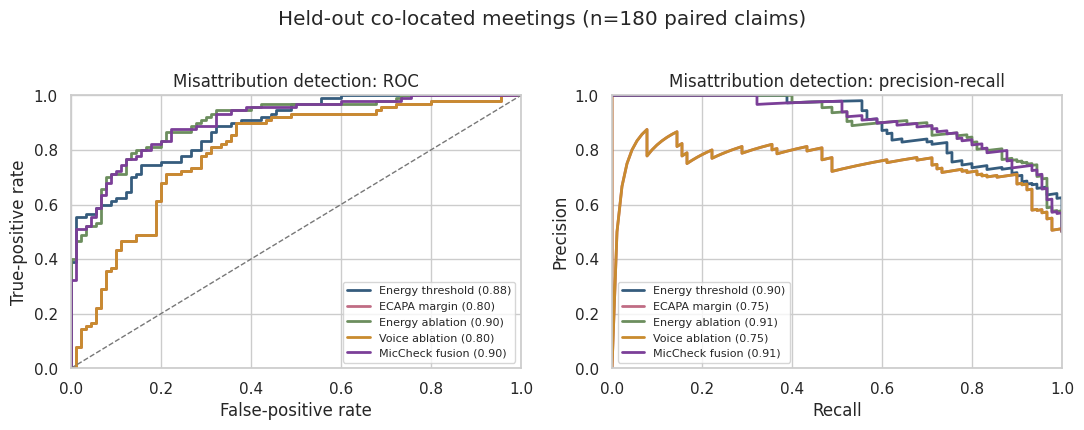

In [21]:
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {
    "Energy threshold": "#355C7D", "ECAPA margin": "#C06C84",
    "Energy ablation": "#6C8E5E", "Voice ablation": "#C98B2E",
    "MicCheck fusion": "#7B3F98",
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for method in METHODS:
    false_positive, true_positive, _ = roc_curve(test_scored.y, test_scored[method])
    precision, recall, _ = precision_recall_curve(test_scored.y, test_scored[method])
    auc = results.set_index("method").loc[method, "AUROC"]
    ap = results.set_index("method").loc[method, "AUPRC"]
    axes[0].plot(false_positive, true_positive, label=f"{method} ({auc:.2f})",
                 color=PALETTE[method], linewidth=2)
    axes[1].plot(recall, precision, label=f"{method} ({ap:.2f})",
                 color=PALETTE[method], linewidth=2)
axes[0].plot([0, 1], [0, 1], "--", color="#777777", linewidth=1)
axes[0].set(title="Misattribution detection: ROC", xlabel="False-positive rate",
            ylabel="True-positive rate", xlim=(0, 1), ylim=(0, 1))
axes[1].set(title="Misattribution detection: precision-recall", xlabel="Recall",
            ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
for axis in axes:
    axis.legend(fontsize=8, frameon=True)
fig.suptitle(f"Held-out co-located meetings (n={len(test_scored)} paired claims)", y=1.02)
fig.tight_layout()
fig.savefig(PAPER_ROOT / "main_curves.pdf", bbox_inches="tight")
fig.savefig(REPORT_ROOT / "main_curves.png", dpi=180, bbox_inches="tight")
plt.show()

### 12. Component ablation

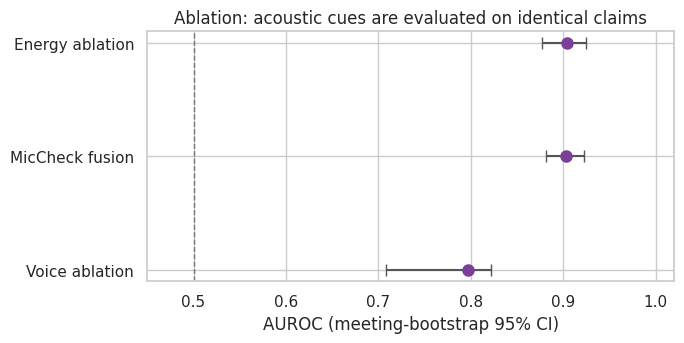

In [22]:
ablation = results[results.method.isin(["Energy ablation", "Voice ablation", "MicCheck fusion"])].copy()
ablation = ablation.sort_values("AUROC")
fig, ax = plt.subplots(figsize=(7, 3.6))
errors = np.vstack([ablation.AUROC - ablation.AUROC_low,
                    ablation.AUROC_high - ablation.AUROC])
ax.errorbar(ablation.AUROC, ablation.method, xerr=errors, fmt="o", markersize=8,
            color="#7B3F98", ecolor="#555555", capsize=4)
ax.axvline(0.5, linestyle="--", color="#777777", linewidth=1)
ax.set(xlabel="AUROC (meeting-bootstrap 95% CI)", ylabel="",
       title="Ablation: acoustic cues are evaluated on identical claims", xlim=(0.45, 1.02))
fig.tight_layout()
fig.savefig(PAPER_ROOT / "ablation.pdf", bbox_inches="tight")
fig.savefig(REPORT_ROOT / "ablation.png", dpi=180, bbox_inches="tight")
plt.show()

### 13. Evidence-window sensitivity

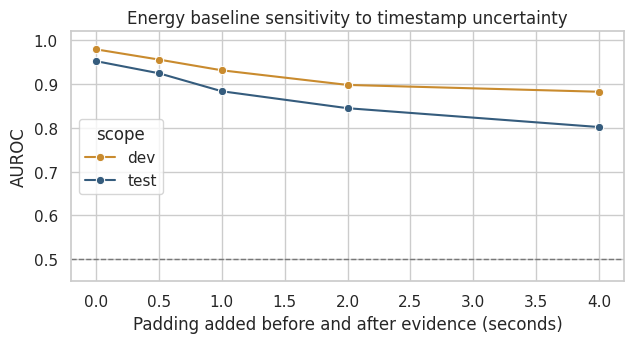

In [23]:
padding_values = [0.0, 0.5, 1.0, 2.0, 4.0]
sensitivity_rows = []
main_pairs = claims[(claims.benchmark == MAIN_BENCHMARK) &
                    claims.meeting.isin(DEV_MEETINGS + TEST_MEETINGS)]
for padding in padding_values:
    local_records = []
    for meeting, group in main_pairs.groupby("meeting"):
        tracks = load_tracks(meeting)
        offsets = meeting_gain_offsets(tracks)
        for row in group.itertuples(index=False):
            feats = energy_features(row, tracks, offsets, pad=padding)
            local_records.append({"claim_id": row.claim_id, "score": -feats["energy_margin_db"]})
    local = main_pairs.merge(pd.DataFrame(local_records), on="claim_id", validate="one_to_one")
    for scope, meetings in (("dev", DEV_MEETINGS), ("test", TEST_MEETINGS)):
        subset = local[local.meeting.isin(meetings)]
        sensitivity_rows.append({"padding_s": padding, "scope": scope,
                                 "AUROC": roc_auc_score(subset.y, subset.score)})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(REPORT_ROOT / "window_sensitivity.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.lineplot(data=sensitivity, x="padding_s", y="AUROC", hue="scope",
             marker="o", palette={"dev": "#C98B2E", "test": "#355C7D"}, ax=ax)
ax.axhline(0.5, linestyle="--", color="#777777", linewidth=1)
ax.set(title="Energy baseline sensitivity to timestamp uncertainty",
       xlabel="Padding added before and after evidence (seconds)", ylabel="AUROC",
       ylim=(0.45, 1.02))
fig.tight_layout()
fig.savefig(PAPER_ROOT / "window_sensitivity.pdf", bbox_inches="tight")
fig.savefig(REPORT_ROOT / "window_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()

### 14. Practical coverage versus residual error

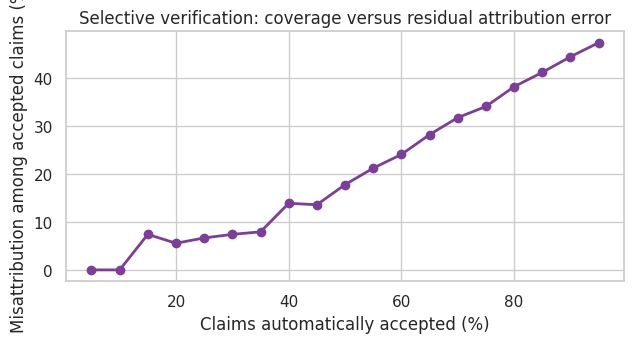

In [24]:
# Accept claims below a flagging threshold. Residual risk is the error rate among accepted claims.
score = test_scored["MicCheck fusion"].to_numpy()
coverage_rows = []
for threshold in np.quantile(score, np.linspace(0.05, 0.95, 19)):
    accepted = score < threshold
    if accepted.sum():
        coverage_rows.append({"coverage": accepted.mean(),
                              "residual_error": test_scored.y.to_numpy()[accepted].mean(),
                              "threshold": threshold})
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(REPORT_ROOT / "coverage_risk.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(100 * coverage.coverage, 100 * coverage.residual_error,
        marker="o", color="#7B3F98", linewidth=2)
ax.set(title="Selective verification: coverage versus residual attribution error",
       xlabel="Claims automatically accepted (%)", ylabel="Misattribution among accepted claims (%)")
fig.tight_layout()
fig.savefig(PAPER_ROOT / "coverage_risk.pdf", bbox_inches="tight")
fig.savefig(REPORT_ROOT / "coverage_risk.png", dpi=180, bbox_inches="tight")
plt.show()

### 15. Negative-control and random-negative checks

In [25]:
comparison_rows = []
for benchmark_name, variant, meetings in (
        ("random/co-located test", "counterfactual_random", TEST_MEETINGS),
        ("hard/co-located stress test", "counterfactual_hard", TEST_MEETINGS),
        ("random/remote control", "counterfactual_random", REMOTE_CONTROLS)):
    subset = claims[(claims.benchmark == variant) & claims.meeting.isin(meetings)]
    if not len(subset):
        continue
    scored = attach_scores(subset)
    for method in METHODS:
        comparison_rows.append({"condition": benchmark_name, "method": method,
                                "n": len(scored), "AUROC": roc_auc_score(scored.y, scored[method])})
controls = pd.DataFrame(comparison_rows)
controls.to_csv(REPORT_ROOT / "control_results.csv", index=False)
display(controls.pivot(index="method", columns="condition", values="AUROC").round(3))

condition,hard/co-located stress test,random/co-located test,random/remote control
method,,,
ECAPA margin,0.753,0.797,0.993
Energy ablation,0.799,0.904,0.996
Energy threshold,0.760,0.883,0.998
MicCheck fusion,0.800,0.903,0.998
Voice ablation,0.753,0.797,0.993


### 16. Commented error examples

In [26]:
threshold = thresholds["MicCheck fusion"]
errors = test_scored.copy()
errors["prediction"] = (errors["MicCheck fusion"] >= threshold).astype(int)
errors["error_type"] = np.select(
    [(errors.y == 0) & (errors.prediction == 1),
     (errors.y == 1) & (errors.prediction == 0)],
    ["false positive", "false negative"], default="correct")
errors["distance_to_threshold"] = abs(errors["MicCheck fusion"] - threshold)
examples = (errors[errors.error_type != "correct"]
            .sort_values(["error_type", "distance_to_threshold"], ascending=[True, False])
            .groupby("error_type", group_keys=False).head(4))
example_columns = ["meeting", "error_type", "claimed_speaker", "true_speaker", "claim",
                   "energy_margin_db", "voice_margin", "MicCheck fusion"]
examples[example_columns].to_csv(REPORT_ROOT / "error_examples.csv", index=False)
display(examples[example_columns].style.format({
    "energy_margin_db": "{:.1f}", "voice_margin": "{:.3f}", "MicCheck fusion": "{:.3f}"}))

print("Interpretation checklist for each example:")
print("- overlap or interruption; very short evidence; bad timestamp; microphone gain/distance;")
print("- repeated proposal or group agreement; laughter/noise; weak enrollment; similar voices.")

,meeting,error_type,claimed_speaker,true_speaker,claim,energy_margin_db,voice_margin,MicCheck fusion
543,045b_EADH,false negative,114,115,de la transmission euh de génération,4.3,0.504,0.063
507,045b_EADH,false negative,114,115,ouais ce serait pas mal,1.0,0.537,0.071
275,025b_EBDH,false negative,073,072,oui c'est oui c'est pas du tout un documentaire ouais ça y ai,5.4,-0.082,0.107
523,045b_EADH,false negative,114,115,en_fait dans le style de brut tu vois ces vidéos là,2.7,0.326,0.151
506,045b_EADH,false positive,115,115,ouais ce serait pas mal,-15.5,-0.537,0.788
430,039b_EDDH,false positive,107,107,est-ce_qu' on est-ce qu on plante la tente,-9.0,-0.137,0.685
302,025b_EBDH,false positive,073,073,c'est pour ça qu il faut savoir ce qu on veut,-10.5,-0.156,0.678
250,025b_EBDH,false positive,071,071,ouais je suis pas d'accord,-8.8,-0.298,0.661


Interpretation checklist for each example:
- overlap or interruption; very short evidence; bad timestamp; microphone gain/distance;
- repeated proposal or group agreement; laughter/noise; weak enrollment; similar voices.


### 17. Natural-claim evaluation, when human labels are available

In [27]:
natural_results = pd.DataFrame()
if len(valid_natural):
    natural = claims[(claims.benchmark == "natural") & claims.meeting.isin(TEST_MEETINGS)]
    if len(natural) and natural.y.nunique() == 2:
        natural_scored = attach_scores(natural)
        natural_results = pd.DataFrame([
            metric_row(natural_scored, method, thresholds[method]) for method in METHODS
        ])
        natural_results.to_csv(REPORT_ROOT / "natural_results.csv", index=False)
        display(natural_results.round(3))
    else:
        print("Natural test claims need examples from both labels before binary evaluation.")
else:
    print("Natural evaluation is pending human annotation; no natural result is inferred.")

,method,n,positives,AUROC,AUPRC,precision,recall,F1,threshold
0,Energy threshold,44,25,0.813,0.881,0.900,0.72,0.800,5.568
1,ECAPA margin,44,25,0.760,0.777,0.704,0.76,0.731,0.070
2,Energy ablation,44,25,0.819,0.876,0.895,0.68,0.773,0.409
3,Voice ablation,44,25,0.760,0.777,0.704,0.76,0.731,0.403
4,MicCheck fusion,44,25,0.821,0.879,0.875,0.56,0.683,0.586


### 18. Export paper-ready LaTeX tables and macros

In [28]:
def latex_escape(value):
    return str(value).replace("&", r"\&").replace("%", r"\%").replace("_", r"\_")

lines = [r"\begin{tabular}{lccccc}", r"\toprule",
         r"Method & AUROC & AUPRC & Prec. & Rec. & F1 \\", r"\midrule"]
for row in results.itertuples(index=False):
    lines.append(f"{latex_escape(row.method)} & {row.AUROC:.3f} & {row.AUPRC:.3f} & "
                 f"{row.precision:.3f} & {row.recall:.3f} & {row.F1:.3f} " + r"\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(PAPER_ROOT / "results_table.tex").write_text("\n".join(lines), encoding="utf-8")

indexed = results.set_index("method")
fusion = indexed.loc["MicCheck fusion"]
baseline = indexed.loc["Energy threshold"]
macros = "\n".join([
    rf"\renewcommand{{\TestClaimCount}}{{{len(test_scored)}}}",
    rf"\renewcommand{{\BaselineAUROC}}{{{baseline.AUROC:.3f}}}",
    rf"\renewcommand{{\FusionAUROC}}{{{fusion.AUROC:.3f}}}",
    rf"\renewcommand{{\FusionAUPRC}}{{{fusion.AUPRC:.3f}}}",
    rf"\renewcommand{{\FusionFOne}}{{{fusion.F1:.3f}}}",
    rf"\renewcommand{{\FusionAUCInterval}}{{[{fusion.AUROC_low:.3f}, {fusion.AUROC_high:.3f}]}}",
])
(PAPER_ROOT / "results_macros.tex").write_text(macros + "\n", encoding="utf-8")
print("Paper assets written to", PAPER_ROOT)

Paper assets written to /content/TRACEMEET/paper/generated
